# Chapitre 9 · Tuning, cross-validation et projet SMS

## Objectif

Une messagerie doit repérer les SMS indésirables à leur réception. Un faux
positif peut masquer un rendez-vous ou un message d'un proche. Un faux négatif
laisse arriver un spam. Nous allons construire puis évaluer ce filtre sur un
corpus de messages réels, étiquetés comme légitimes (ham) ou indésirables (spam).

Nous suivons tout le parcours d'un projet. Définir les entrées et les erreurs,
réserver le test, explorer l'apprentissage, comparer des pipelines, choisir un
seuil, puis analyser le résultat final. Les expériences sur les plis et SMOTE
préparent le projet. Les corrections sont repliables.

## Environnement

Ouvrir ce notebook à côté du dossier **data** fourni. Installer dans un
environnement de cours avec
`python -m pip install -r requirements.txt`.
Le fichier original est inclus et l'exécution fonctionne sans réseau après installation.
Versions d'exécution enregistrées dans la première cellule.

In [1]:
from pathlib import Path
import hashlib
import json
import time
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import imblearn
from IPython.display import display
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GroupKFold, KFold, StratifiedKFold, StratifiedGroupKFold,
    RepeatedStratifiedKFold, ShuffleSplit, LeaveOneOut, TimeSeriesSplit,
    GridSearchCV, RandomizedSearchCV, ParameterGrid,
    cross_validate, cross_val_score, train_test_split, validation_curve,
)
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

%matplotlib inline
pd.set_option('display.max_columns', 10)
plt.rcParams.update({
    'figure.dpi': 135, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlepad': 9,
})
seed = 9
blue, red = '#265977', '#8c1515'
print('scikit-learn', sklearn.__version__)
print('imbalanced-learn', imblearn.__version__)
print('NumPy', np.__version__, '| pandas', pd.__version__)

scikit-learn 1.4.2
imbalanced-learn 0.12.4
NumPy 1.26.4 | pandas 2.3.2


## 1. Comprendre les stratégies de cross-validation

Un **paramètre** est appris par `fit`, par exemple les coefficients de Logistic
Regression. Un **hyperparamètre** règle le calcul avant cet ajustement, par exemple
`C`, `max_depth` ou le nombre de voisins de SMOTE.

Dans la figure, 24 observations fictives sont placées dans un ordre choisi pour
rendre les différences visibles. Chaque ligne est un ajustement. Bleu désigne
l'apprentissage, rouge la validation, blanc une observation inutilisée.
Le `gap` de TimeSeriesSplit écarte ici une observation entre les deux blocs.

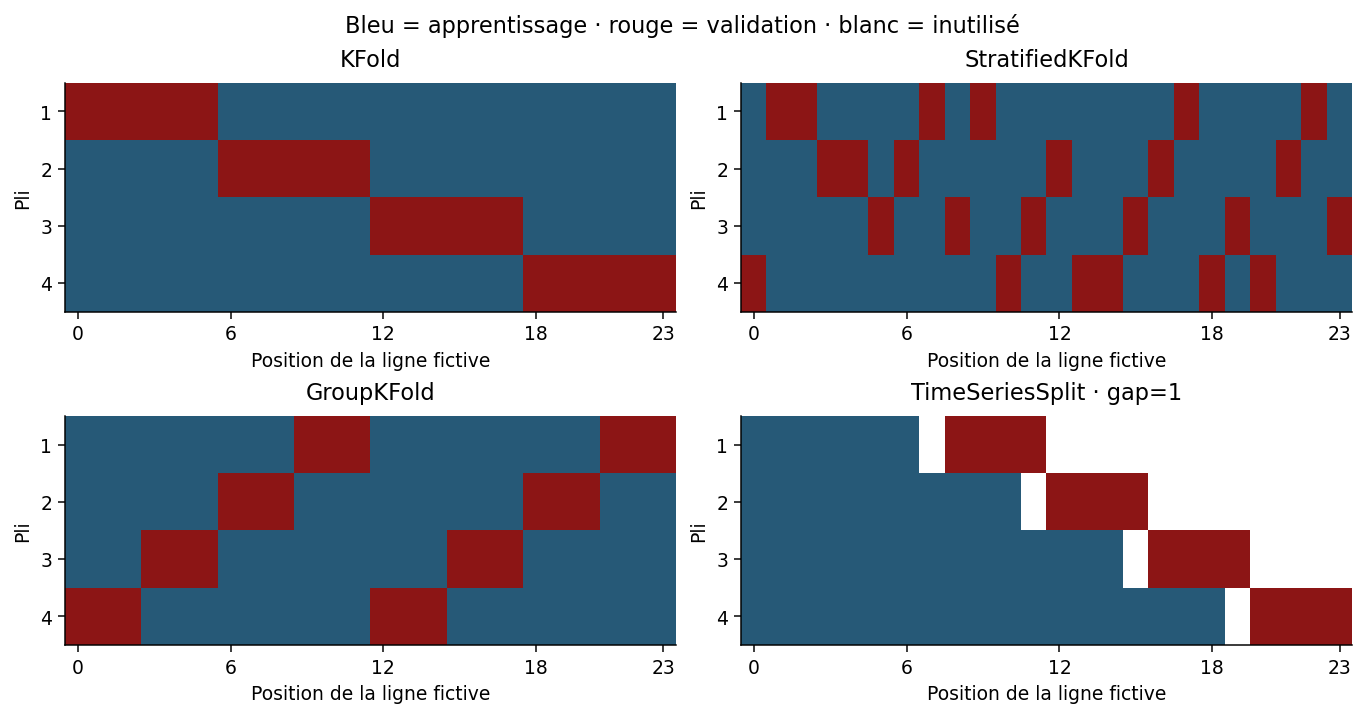

In [2]:
X_demo = np.arange(24).reshape(-1, 1)
y_demo = np.array([0] * 18 + [1] * 6)
groups_demo = np.repeat(np.arange(8), 3)
splitters = {
    'KFold': KFold(n_splits=4),
    'StratifiedKFold': StratifiedKFold(n_splits=4, shuffle=True, random_state=seed),
    'GroupKFold': GroupKFold(n_splits=4),
    'TimeSeriesSplit · gap=1': TimeSeriesSplit(n_splits=4, gap=1),
}
fig, axes = plt.subplots(2, 2, figsize=(10, 5.2), layout='constrained')
for ax, (name, splitter) in zip(axes.flat, splitters.items()):
    assignments = np.zeros((4, len(X_demo)))
    iterator = splitter.split(X_demo, y_demo, groups_demo) if name == 'GroupKFold' else splitter.split(X_demo, y_demo)
    for fold, (train_idx, valid_idx) in enumerate(iterator):
        assignments[fold, train_idx] = 1
        assignments[fold, valid_idx] = 2
    from matplotlib.colors import ListedColormap
    ax.imshow(assignments, aspect='auto', interpolation='nearest',
              cmap=ListedColormap(['#ffffff', blue, red]), vmin=0, vmax=2)
    ax.set(title=name, xlabel='Position de la ligne fictive', ylabel='Pli',
           yticks=range(4), yticklabels=range(1, 5), xticks=[0, 6, 12, 18, 23])
fig.suptitle('Bleu = apprentissage · rouge = validation · blanc = inutilisé')
plt.show()

**À vous.** Dans KFold sans mélange, où tombent les six observations positives ?
Qu'arrive-t-il dans le dernier pli ?

<details><summary>Correction</summary>
La validation du dernier pli ne contient que la classe 1. Son apprentissage ne
contient que la classe 0. La stratification répartit les classes dans les plis.
Elle conserve une proportion, mais ne protège pas des dépendances entre clients
ou dates. GroupKFold regroupe les lignes d'une même entité. TimeSeriesSplit garde
l'ordre et ajuste sur le passé.
</details>

### Choisir un nombre de répétitions utile

RepeatedStratifiedKFold refait les partitions avec d'autres tirages. ShuffleSplit
effectue des séparations aléatoires dont les validations peuvent se recouvrir.
LeaveOneOut réserve une seule ligne à la fois. Ces scores sont dépendants, car
leurs apprentissages se recouvrent. L'écart-type entre plis décrit une dispersion,
sans fournir directement un intervalle de confiance.

In [3]:
cv_rows = []
for name, splitter in splitters.items():
    iterator = splitter.split(X_demo, y_demo, groups_demo) if name == 'GroupKFold' else splitter.split(X_demo, y_demo)
    for fold, (train_idx, valid_idx) in enumerate(iterator, 1):
        cv_rows.append({
            'method': name, 'fold': fold, 'train_size': len(train_idx),
            'valid_size': len(valid_idx), 'valid_positives': y_demo[valid_idx].sum(),
        })
display(pd.DataFrame(cv_rows).pivot(index='method', columns='fold', values='valid_positives'))
print('RepeatedStratifiedKFold, 5 plis × 3 répétitions :',
      RepeatedStratifiedKFold(n_splits=5, n_repeats=3).get_n_splits())
print('LeaveOneOut sur 24 lignes :', LeaveOneOut().get_n_splits(X_demo))

RepeatedStratifiedKFold, 5 plis × 3 répétitions : 15
LeaveOneOut sur 24 lignes : 24


fold,1,2,3,4
method,,,,
GroupKFold,3,3,0,0
KFold,0,0,0,6
StratifiedKFold,1,1,2,2
TimeSeriesSplit · gap=1,0,0,2,4


## 2. SMOTE à la main et dans imbalanced-learn

**SMOTE** signifie Synthetic Minority Over-sampling Technique. On choisit un
exemple minoritaire `x`, l'un de ses voisins minoritaires `x_neighbor`, puis
un nombre `fraction` entre 0 et 1. Le point synthétique est

$$x_{new}=x+fraction\,(x_{neighbor}-x).$$

Le point se situe sur le segment entre les deux exemples. Standardiser les
variables numériques avant de calculer les voisins rend leurs échelles comparables.
Le nombre de voisins doit être inférieur au nombre de minoritaires disponibles
dans **chaque pli d'apprentissage**.

In [4]:
x = np.array([2.0, 4.0])
x_neighbor = np.array([4.0, 8.0])
fraction = 0.25
x_new = x + fraction * (x_neighbor - x)
print('Point synthétique :', x_new)

Point synthétique : [2.5 5. ]


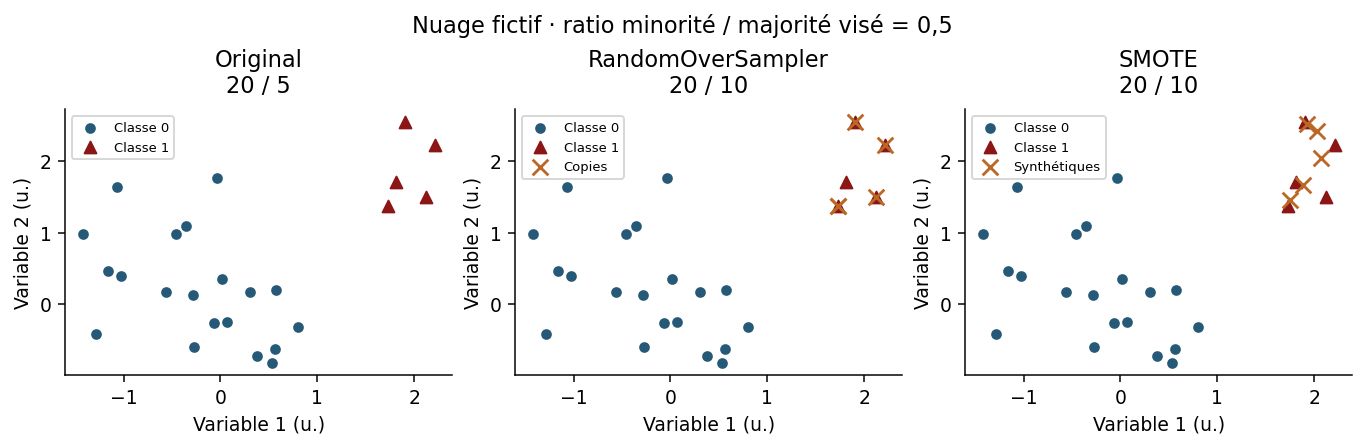

In [5]:
rng = np.random.default_rng(seed)
X_toy = np.vstack([rng.normal([0, 0], 0.7, (20, 2)),
                   rng.normal([2.2, 1.8], 0.4, (5, 2))])
y_toy = np.array([0] * 20 + [1] * 5)
samplers = {
    'Original': None,
    'RandomOverSampler': RandomOverSampler(sampling_strategy=0.5, random_state=seed),
    'SMOTE': SMOTE(sampling_strategy=0.5, k_neighbors=2, random_state=seed),
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), layout='constrained')
for ax, (name, sampler) in zip(axes, samplers.items()):
    X_resampled, y_resampled = (X_toy, y_toy) if sampler is None else sampler.fit_resample(X_toy, y_toy)
    ax.scatter(X_toy[y_toy == 0, 0], X_toy[y_toy == 0, 1], color=blue, s=22, label='Classe 0')
    ax.scatter(X_toy[y_toy == 1, 0], X_toy[y_toy == 1, 1], color=red, marker='^', s=40, label='Classe 1')
    if sampler is not None:
        added = X_resampled[len(X_toy):]
        ax.scatter(added[:, 0], added[:, 1], color='#bb6827', marker='x', s=70,
                   label='Copies' if name == 'RandomOverSampler' else 'Synthétiques')
    ax.set(title=f'{name}\n{sum(y_resampled == 0)} / {sum(y_resampled == 1)}',
           xlabel='Variable 1 (u.)', ylabel='Variable 2 (u.)')
    ax.legend(fontsize=7, loc='upper left')
fig.suptitle('Nuage fictif · ratio minorité / majorité visé = 0,5')
plt.show()

Le nuage contient 20 majoritaires et 5 minoritaires. Le ratio demandé est
minorité / majorité, donc 0,5 conduit à 10 minoritaires pour 20 majoritaires.
La proportion minoritaire finale est 10 / 30, soit un tiers. Le sampler ne
doit jamais modifier les lignes réservées pour évaluer le modèle.

## 3. Projet · repérer les SMS indésirables

Le corpus **SMS Spam Collection** contient des SMS en anglais et leurs étiquettes.
Ham désigne un message légitime. Spam désigne un message indésirable.
Le texte est disponible au moment de la décision. Nous simulons le rangement
des messages signalés dans un dossier que l'utilisateur peut consulter.

La source inclut des messages recueillis auprès d'étudiants. Le fichier est
ancien et ne représente pas à lui seul les SMS français ou les arnaques actuelles.
Source, Almeida et Hidalgo (2011), UCI, DOI
[10.24432/C5CC84](https://doi.org/10.24432/C5CC84), CC BY 4.0.

### Audit et doublons

On lit le texte original sans supprimer la ponctuation. Une copie normalisée
sert seulement à repérer les textes répétés, en ignorant la casse et les
espaces répétés. Ces copies doivent être retirées avant le partage pour limiter
la mémorisation de SMS déjà vus. Cette règle est fixée avant les essais.

In [6]:
data_path = Path('data/SMSSpamCollection')
expected_sha256 = '7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d'
raw_bytes = data_path.read_bytes()
assert hashlib.sha256(raw_bytes).hexdigest() == expected_sha256
rows = [line.split('\t', 1) for line in raw_bytes.decode('utf-8').splitlines() if line.strip()]
raw_data = pd.DataFrame(rows, columns=['label', 'text'])
assert raw_data.shape == (5574, 2)
assert set(raw_data['label']) == {'ham', 'spam'}
assert raw_data['text'].str.strip().ne('').all()
raw_data['normalized_text'] = (
    raw_data['text'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
)
label_counts = raw_data.groupby('normalized_text')['label'].nunique()
conflicting_texts = label_counts[label_counts > 1].index
data = (
    raw_data.loc[~raw_data['normalized_text'].isin(conflicting_texts)]
    .drop_duplicates('normalized_text').copy()
)
data['is_spam'] = data['label'].eq('spam').astype(int)
print('Messages bruts :', len(raw_data))
print('Textes aux étiquettes contradictoires :', len(conflicting_texts))
print('Répétitions retirées :', len(raw_data) - len(data))
print('Messages conservés :', len(data))
display(data['label'].value_counts().to_frame('count'))

Messages bruts : 5574
Textes aux étiquettes contradictoires : 0
Répétitions retirées : 415
Messages conservés : 5159


,count
label,
ham,4517
spam,642


Le fichier contient 5 574 messages, dont 747 spams. L'audit trouve 415 répétitions
selon la règle normalisée et aucun texte aux étiquettes contradictoires.
Il reste 5 159 textes, dont 642 spams.

Le texte original est conservé pour le modèle. La normalisation utilisée pour
l'audit n'introduit aucune colonne dans les entrées. Elle sert à vérifier que
des copies ne traversent pas les séparations.

In [7]:
X = data['text']
y = data['is_spam']
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=seed,
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=seed,
)
train_texts = set(data.loc[X_train.index, 'normalized_text'])
valid_texts = set(data.loc[X_valid.index, 'normalized_text'])
test_texts = set(data.loc[X_test.index, 'normalized_text'])
assert train_texts.isdisjoint(valid_texts)
assert train_texts.isdisjoint(test_texts)
assert valid_texts.isdisjoint(test_texts)
print('Apprentissage / validation de seuil / test :',
      len(X_train), len(X_valid), len(X_test))
print('Spams dans l’apprentissage :', int(y_train.sum()))

Apprentissage / validation de seuil / test : 3095 1032 1032
Spams dans l’apprentissage : 385


### EDA · combien de spams et à quoi ressemblent les textes ?

L'exploration suivante porte uniquement sur l'apprentissage. Nous comparons
les effectifs, les longueurs et la présence de mots. Un long message peut
être légitime. Une promotion ou le mot « free » ne suffisent pas, à eux seuls,
à fixer la classe.

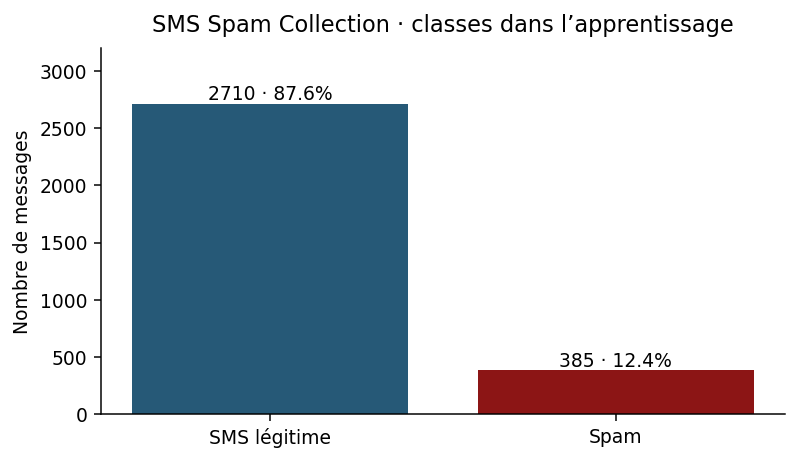

In [8]:
class_counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.8, 3.3), layout='constrained')
bars = ax.bar(['SMS légitime', 'Spam'], class_counts, color=[blue, red])
for bar, count in zip(bars, class_counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 35,
            f'{count} · {count / len(y_train):.1%}', ha='center')
ax.set(ylabel='Nombre de messages', ylim=(0, class_counts.max() * 1.18),
       title='SMS Spam Collection · classes dans l’apprentissage')
plt.show()

Longueur maximale dans l’apprentissage : 910


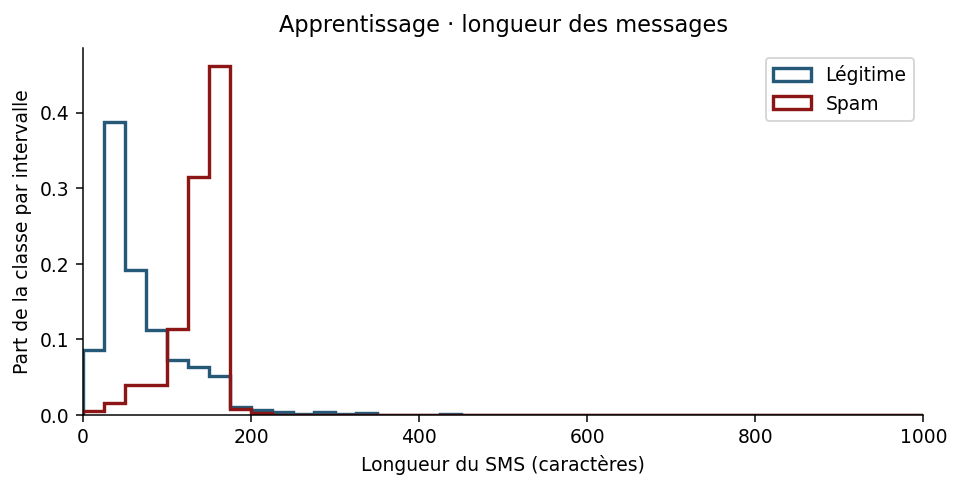

In [9]:
fig, ax = plt.subplots(figsize=(7.0, 3.5), layout='constrained')
lengths = X_train.str.len()
for target, color, name in [(0, blue, 'Légitime'), (1, red, 'Spam')]:
    ax.hist(lengths[y_train == target], bins=np.arange(0, 1001, 25),
            density=False, weights=np.ones(sum(y_train == target)) / sum(y_train == target),
            histtype='step', linewidth=1.8, color=color, label=name)
ax.set(xlabel='Longueur du SMS (caractères)', ylabel='Part de la classe par intervalle',
       title='Apprentissage · longueur des messages', xlim=(0, 1000))
ax.legend()
plt.show()
print('Longueur maximale dans l’apprentissage :', lengths.max())

Le graphique limite l'axe à 1 000 caractères et rapporte chaque effectif à la
taille de sa classe. Les messages plus longs restent dans l'apprentissage.
On compare les formes sans donner davantage de poids à la classe majoritaire.

### Transformer les mots en nombres

Un vocabulaire définit une colonne par mot. Avec « free offer », « offer today »
et « meet today », la matrice de comptage contient des nombres d'occurrences.
TF–IDF pondère ensuite ces occurrences. Un mot présent dans beaucoup de documents
reçoit un poids IDF plus faible qu'un mot rare. Avec les options par défaut,
IDF(t) = log((1 + nombre de documents)/(1 + documents contenant t)) + 1.
Chaque ligne est ensuite normalisée pour avoir une norme euclidienne de 1.

In [10]:
demo_texts = ['free offer', 'offer today', 'meet today']
demo_vectorizer = TfidfVectorizer()
demo_matrix = demo_vectorizer.fit_transform(demo_texts)
display(pd.DataFrame(
    demo_matrix.toarray(), columns=demo_vectorizer.get_feature_names_out(),
    index=demo_texts,
).round(3))

,free,meet,offer,today
free offer,0.796,0.000,0.605,0.000
offer today,0.000,0.000,0.707,0.707
meet today,0.000,0.796,0.000,0.605


La matrice est creuse, car un SMS contient une petite partie du vocabulaire.
Une matrice creuse stocke surtout les cellules non nulles. Dans le projet,
<code>ngram_range=(1,2)</code> ajoute les paires de mots consécutifs,
<code>min_df=2</code> demande au moins deux documents pour retenir un terme et
<code>max_features=5000</code> limite le vocabulaire. Le vocabulaire et les IDF
sont appris dans le pli d'apprentissage.

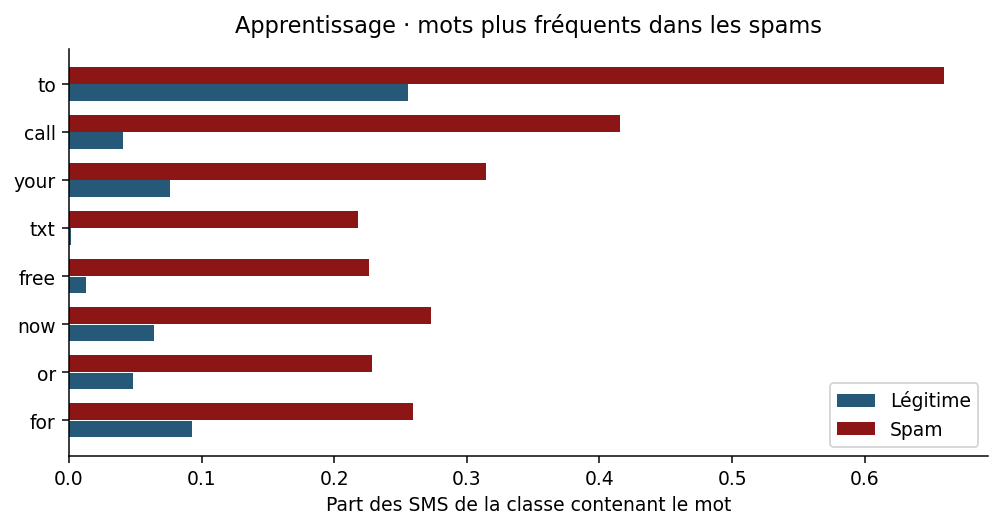

In [11]:
word_probe = TfidfVectorizer(use_idf=False, norm=None, binary=True,
                            min_df=5, max_features=2000)
word_presence = word_probe.fit_transform(X_train)
spam_rates = np.asarray(word_presence[y_train.to_numpy() == 1].mean(axis=0)).ravel()
ham_rates = np.asarray(word_presence[y_train.to_numpy() == 0].mean(axis=0)).ravel()
top_indices = np.argsort(spam_rates - ham_rates)[-8:]
words = word_probe.get_feature_names_out()[top_indices]
fig, ax = plt.subplots(figsize=(7.3, 3.8), layout='constrained')
positions = np.arange(len(words))
ax.barh(positions - 0.18, ham_rates[top_indices], height=0.35, color=blue, label='Légitime')
ax.barh(positions + 0.18, spam_rates[top_indices], height=0.35, color=red, label='Spam')
ax.set(yticks=positions, yticklabels=words, xlabel='Part des SMS de la classe contenant le mot',
       title='Apprentissage · mots plus fréquents dans les spams')
ax.legend()
plt.show()

### Pipeline de texte et modèles

Le premier modèle est Logistic Regression, vu au chapitre 8. Nous comparons
aussi **Multinomial Naive Bayes**. Il estime des poids de mots par classe et
combine les contributions des mots d'un message sous une hypothèse d'indépendance
conditionnelle. Son hyperparamètre <code>alpha</code> ajoute du lissage afin
d'éviter des fréquences nulles. Il peut utiliser les poids TF–IDF non négatifs.

La chaîne est TF–IDF → sampler → modèle. Le projet garde la normalisation
TF–IDF et la matrice creuse. SMOTE interpole ici des vecteurs de poids de mots.
Un vecteur interpolé n'est pas un nouveau SMS rédigé. Le voisinage en grande
dimension peut aussi être peu représentatif. La comparaison inclut donc le
modèle sans sampling, les poids de classes et les copies aléatoires.

In [12]:
base_pipeline = ImbPipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000)),
    ('sampler', 'passthrough'),
    ('model', LogisticRegression(solver='liblinear', max_iter=2000, random_state=seed)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
scoring = {'ap': 'average_precision', 'roc_auc': 'roc_auc', 'recall': 'recall'}

### Métriques et référence

La référence prédit toujours « légitime ». Elle peut atteindre une accuracy
élevée avec un recall des spams nul. L'Average Precision (AP) compare le classement
des spams. Un score constant donne une AP égale à leur proportion dans l'échantillon.
On rapporte aussi precision, recall, FP et FN une fois la règle de filtrage fixée.

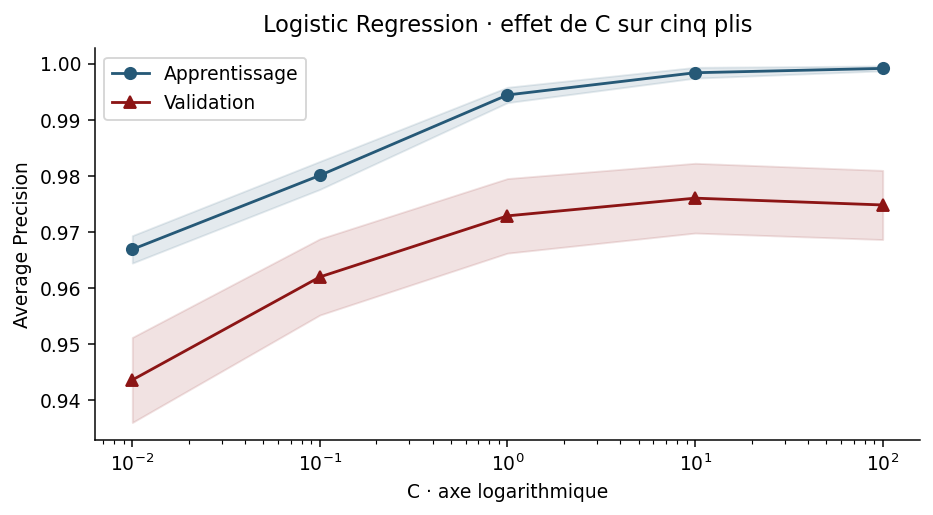

In [13]:
C_values = np.array([0.01, 0.1, 1, 10, 100])
train_curve, valid_curve = validation_curve(
    base_pipeline, X_train, y_train, param_name='model__C', param_range=C_values,
    cv=cv, scoring='average_precision', error_score='raise',
)
fig, ax = plt.subplots(figsize=(6.8, 3.7), layout='constrained')
for values, color, name, marker in [
    (train_curve, blue, 'Apprentissage', 'o'),
    (valid_curve, red, 'Validation', '^'),
]:
    mean_values, std_values = values.mean(axis=1), values.std(axis=1)
    ax.plot(C_values, mean_values, marker=marker, color=color, label=name)
    ax.fill_between(C_values, mean_values - std_values, mean_values + std_values,
                    color=color, alpha=0.12)
ax.set(xscale='log', xlabel='C · axe logarithmique', ylabel='Average Precision',
       title='Logistic Regression · effet de C sur cinq plis')
ax.legend()
plt.show()

In [14]:
strategies = {
    'Majority baseline': clone(base_pipeline).set_params(model=DummyClassifier(strategy='most_frequent')),
    'Logistic Regression': clone(base_pipeline),
    'Class weights': clone(base_pipeline).set_params(model__class_weight='balanced'),
    'RandomUnderSampler': clone(base_pipeline).set_params(
        sampler=RandomUnderSampler(sampling_strategy=0.5, random_state=seed)),
    'RandomOverSampler': clone(base_pipeline).set_params(
        sampler=RandomOverSampler(sampling_strategy=0.5, random_state=seed)),
    'SMOTE': clone(base_pipeline).set_params(
        sampler=SMOTE(sampling_strategy=0.5, k_neighbors=5, random_state=seed)),
    'Multinomial Naive Bayes': clone(base_pipeline).set_params(model=MultinomialNB(alpha=1)),
}
comparison_rows = []
for name, estimator in strategies.items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring,
                            error_score='raise', return_train_score=True)
    comparison_rows.append({
        'strategy': name, 'cv_ap': scores['test_ap'].mean(),
        'cv_ap_std': scores['test_ap'].std(), 'cv_recall_at_0.5': scores['test_recall'].mean(),
        'train_ap': scores['train_ap'].mean(), 'fit_seconds': scores['fit_time'].mean(),
    })
comparison = pd.DataFrame(comparison_rows).sort_values('cv_ap', ascending=False)
display(comparison.round(3).reset_index(drop=True))

,strategy,cv_ap,cv_ap_std,cv_recall_at_0.5,train_ap,fit_seconds
0,Class weights,0.974,0.006,0.927,0.997,0.035
1,RandomOverSampler,0.974,0.007,0.888,0.997,0.036
2,Logistic Regression,0.973,0.007,0.644,0.994,0.035
3,SMOTE,0.973,0.007,0.873,0.997,0.039
4,RandomUnderSampler,0.969,0.008,0.868,0.991,0.034
5,Multinomial Naive Bayes,0.953,0.013,0.639,0.989,0.033
6,Majority baseline,0.124,0.000,0.000,0.124,0.033


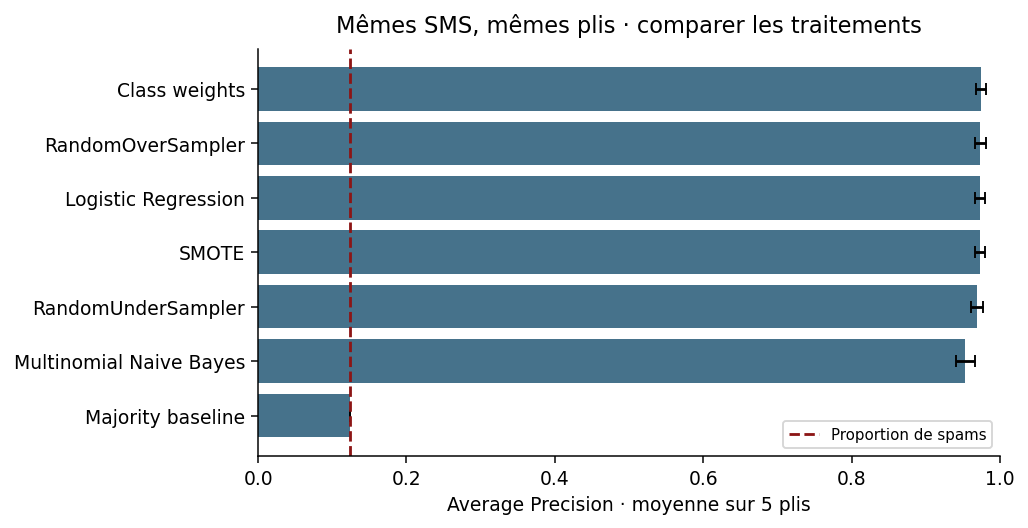

In [15]:
ordered = comparison.sort_values('cv_ap')
fig, ax = plt.subplots(figsize=(7.5, 3.8), layout='constrained')
ax.barh(ordered['strategy'], ordered['cv_ap'], xerr=ordered['cv_ap_std'],
        color=blue, alpha=0.85, capsize=3)
ax.axvline(y_train.mean(), color=red, linestyle='--', label='Proportion de spams')
ax.set(xlabel='Average Precision · moyenne sur 5 plis', xlim=(0, 1),
       title='Mêmes SMS, mêmes plis · comparer les traitements')
ax.legend(loc='lower right', fontsize=8)
plt.show()

Les rappels utilisent le seuil par défaut. Ils décrivent une décision donnée,
tandis que l'AP évalue le classement produit par les scores. Les bandes indiquent
un écart-type entre les cinq validations.

## 4. Tuning et analyse des résultats de CV

On explore Logistic Regression avec ou sans poids, Logistic Regression avec
SMOTE, puis Multinomial Naive Bayes. L'option unigrammes ou unigrammes+bigrams
est aussi réglable. Chaque pli apprend son vocabulaire.

In [16]:
param_distributions = [
    {
        'model': [LogisticRegression(solver='liblinear', max_iter=2000, random_state=seed)],
        'sampler': ['passthrough'], 'model__C': loguniform(0.01, 100),
        'model__class_weight': [None, 'balanced'],
        'tfidf__ngram_range': [(1, 1), (1, 2)],
    },
    {
        'model': [LogisticRegression(solver='liblinear', max_iter=2000, random_state=seed)],
        'sampler': [SMOTE(random_state=seed)], 'model__C': loguniform(0.01, 100),
        'sampler__sampling_strategy': [0.5, 1.0], 'sampler__k_neighbors': [3, 5],
        'tfidf__ngram_range': [(1, 1), (1, 2)],
    },
    {
        'model': [MultinomialNB()], 'model__alpha': loguniform(0.01, 10),
        'sampler': ['passthrough'], 'tfidf__ngram_range': [(1, 1), (1, 2)],
    },
]
search = RandomizedSearchCV(
    base_pipeline, param_distributions, n_iter=18, cv=cv,
    scoring=scoring, refit='ap', random_state=seed,
    return_train_score=True, error_score='raise', n_jobs=1,
)
start = time.perf_counter()
search.fit(X_train, y_train)
print('Durée mesurée (s) :', round(time.perf_counter() - start, 1))
print('Meilleure AP CV :', round(search.best_score_, 4))
print('Meilleurs paramètres :', search.best_params_)
best_pipeline = search.best_estimator_

Durée mesurée (s) : 5.5
Meilleure AP CV : 0.9736
Meilleurs paramètres : {'model': MultinomialNB(), 'model__alpha': 0.12398897510295001, 'sampler': 'passthrough', 'tfidf__ngram_range': (1, 2)}


In [17]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results['model_name'] = cv_results['param_model'].map(lambda estimator: type(estimator).__name__)
top_results = cv_results.sort_values('rank_test_ap')[[
    'model_name', 'mean_train_ap', 'mean_test_ap', 'std_test_ap', 'mean_fit_time',
]].head(5)
display(top_results.round(4).reset_index(drop=True))
display(pd.Series(search.best_params_, name='value').to_frame())
best_reference = comparison.iloc[0]
if best_reference['cv_ap'] > search.best_score_:
    best_pipeline = clone(strategies[best_reference['strategy']]).fit(X_train, y_train)
    best_cv_score = float(best_reference['cv_ap'])
    selection_source = f"Comparatif initial · {best_reference['strategy']}"
else:
    best_pipeline = search.best_estimator_
    best_cv_score = float(search.best_score_)
    selection_source = 'RandomizedSearchCV'
print('Candidat conservé :', selection_source)
print('AP CV retenue :', round(best_cv_score, 4))

Candidat conservé : Comparatif initial · Class weights
AP CV retenue : 0.9742


,model_name,mean_train_ap,mean_test_ap,std_test_ap,mean_fit_time
0,MultinomialNB,0.9986,0.9736,0.0091,0.0330
1,LogisticRegression,0.9985,0.9721,0.0087,0.0154
2,MultinomialNB,0.9993,0.9717,0.0107,0.0329
3,LogisticRegression,0.9930,0.9707,0.0061,0.0349
4,MultinomialNB,0.9993,0.9707,0.0111,0.0331


,value
model,MultinomialNB()
model__alpha,0.123989
sampler,passthrough
tfidf__ngram_range,"(1, 2)"


18 configurations et 5 plis donnent 90 ajustements, puis un refit sur
l'apprentissage. La sélection compare aussi les configurations du comparatif
initial, sur les mêmes plis. Une recherche aléatoire peut manquer un réglage
simple déjà essayé. On conserve la meilleure AP moyenne observée parmi ces
candidats, et on réajuste sa chaîne sur l'apprentissage. Le meilleur score
interne reste un score de sélection.
La démonstration suivante évalue une recherche plus courte avec une nested CV,
toujours sur l'apprentissage. Ses scores externes concernent cette procédure
sur trois valeurs de C.

In [18]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=21)
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=22)
inner_search = GridSearchCV(
    clone(base_pipeline), {'model__C': [0.1, 1, 10]},
    scoring='average_precision', cv=inner_cv,
)
outer_scores = cross_val_score(
    inner_search, X_train, y_train, cv=outer_cv, scoring='average_precision',
    error_score='raise',
)
print('AP externes :', np.round(outer_scores, 3))
print('Moyenne externe :', round(outer_scores.mean(), 3))

AP externes : [0.982 0.965 0.972]
Moyenne externe : 0.973


## 5. Choisir le seuil selon le coût des erreurs

Le filtre range les messages signalés dans un dossier indésirables. Un faux
positif peut masquer un SMS attendu. La règle pédagogique est fixée avant le
calcul. Parmi les seuils atteignant **au moins 95 % de precision sur validation**,
retenir celui qui détecte le plus de spams, donc qui a le meilleur recall.
En cas d'égalité, conserver le seuil le plus élevé.

Cette contrainte est mesurée sur la validation. Son niveau sur de nouveaux SMS
peut varier. Un score prédit n'est interprétable comme probabilité que si sa
calibration a été vérifiée.

In [19]:
valid_scores = best_pipeline.predict_proba(X_valid)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(y_valid, valid_scores)
eligible = np.flatnonzero(precision_values[:-1] >= 0.95)
if len(eligible) == 0:
    raise ValueError('No threshold meets the target')
eligible_recall = recall_values[:-1][eligible]
best_recall = eligible_recall.max()
ties = eligible[np.isclose(eligible_recall, best_recall, rtol=0, atol=1e-12)]
threshold_index = ties[np.argmax(thresholds[ties])]
decision_threshold = float(thresholds[threshold_index])
valid_predictions = (valid_scores >= decision_threshold).astype(int)
print('Seuil choisi :', round(decision_threshold, 4))
print('Precision validation :', round(precision_score(y_valid, valid_predictions), 4))
print('Recall validation :', round(recall_score(y_valid, valid_predictions), 4))
assert precision_score(y_valid, valid_predictions) >= 0.95

Seuil choisi : 0.5969
Precision validation : 0.9752
Recall validation : 0.9147


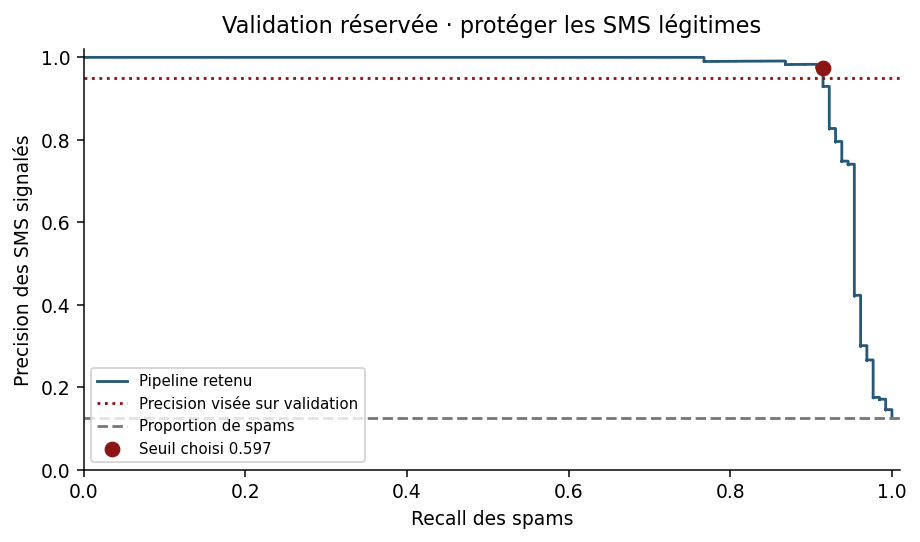

In [20]:
fig, ax = plt.subplots(figsize=(6.7, 3.9), layout='constrained')
ax.step(recall_values, precision_values, where='post', color=blue, label='Pipeline retenu')
ax.axhline(0.95, color=red, linestyle=':', label='Precision visée sur validation')
ax.axhline(y_valid.mean(), color='#777777', linestyle='--', label='Proportion de spams')
ax.scatter([recall_score(y_valid, valid_predictions)], [precision_score(y_valid, valid_predictions)],
           color=red, s=55, label=f'Seuil choisi {decision_threshold:.3f}', zorder=4)
ax.set(xlabel='Recall des spams', ylabel='Precision des SMS signalés',
       title='Validation réservée · protéger les SMS légitimes',
       xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc='lower left', fontsize=8)
plt.show()

### Figer le pipeline et ouvrir le test

Le modèle conserve son ajustement sur l'apprentissage et le seuil vient de la
validation. Un refit modifierait les scores et demanderait de revalider le seuil.
Les deux règles annoncées avant lecture du test sont 0,5 et le seuil validé.

In [21]:
test_scores = best_pipeline.predict_proba(X_test)[:, 1]
test_rows = []
for rule, threshold in [('Default 0.5', 0.5), ('Validated threshold', decision_threshold)]:
    predictions = (test_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    test_rows.append({
        'rule': rule, 'threshold': threshold, 'precision': precision_score(y_test, predictions),
        'recall': recall_score(y_test, predictions), 'f1': f1_score(y_test, predictions),
        'balanced_accuracy': balanced_accuracy_score(y_test, predictions),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
    })
test_results = pd.DataFrame(test_rows)
test_ap = average_precision_score(y_test, test_scores)
test_roc_auc = roc_auc_score(y_test, test_scores)
display(test_results.round(4))
print('Test :', len(y_test), 'SMS, dont', int(y_test.sum()), 'spams')
print('AP test :', round(test_ap, 4), '| ROC AUC test :', round(test_roc_auc, 4))
final_predictions = (test_scores >= decision_threshold).astype(int)

Test : 1032 SMS, dont 128 spams
AP test : 0.9704 | ROC AUC test : 0.9927


,rule,threshold,precision,recall,f1,balanced_accuracy,TP,FP,FN,TN
0,Default 0.5,0.5000,0.8889,0.9375,0.9125,0.9605,120,15,8,889
1,Validated threshold,0.5969,0.9187,0.8828,0.9004,0.9359,113,10,15,894


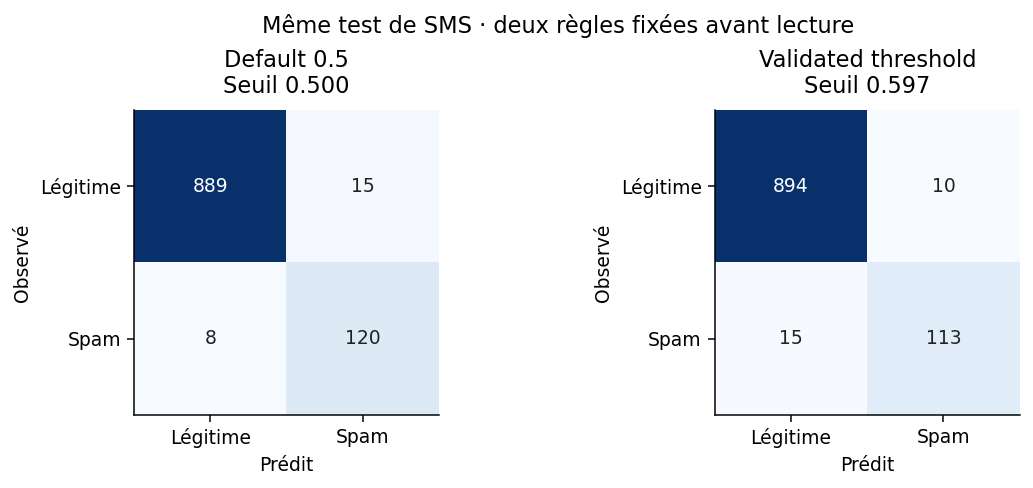

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5), layout='constrained')
for ax, row in zip(axes, test_rows):
    matrix = np.array([[row['TN'], row['FP']], [row['FN'], row['TP']]])
    ax.imshow(matrix, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center',
                    color='white' if matrix[i, j] > matrix.max()*0.5 else '#222222')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Légitime', 'Spam'],
           yticklabels=['Légitime', 'Spam'], xlabel='Prédit', ylabel='Observé',
           title=f"{row['rule']}\nSeuil {row['threshold']:.3f}")
fig.suptitle('Même test de SMS · deux règles fixées avant lecture')
plt.show()

## 6. Comprendre les erreurs du filtre

Les FP sont des messages légitimes envoyés vers les indésirables. Les FN sont
des spams laissés dans la boîte principale. Lire quelques erreurs aide à
comprendre le résultat. Les textes affichés sont tronqués et les longues suites
de chiffres masquées pour garder l'analyse lisible.

In [23]:
error_table = pd.DataFrame({'text': X_test, 'target': y_test,
                            'score': test_scores, 'prediction': final_predictions})
error_table['excerpt'] = (
    error_table['text'].str.replace(r'\d{5,}', '[number]', regex=True).str.slice(0, 105)
)
false_negatives = error_table.query('target == 1 and prediction == 0').sort_values('score')
false_positives = error_table.query('target == 0 and prediction == 1').sort_values('score', ascending=False)
display(false_negatives[['excerpt', 'score']].head(4).round(3))
display(false_positives[['excerpt', 'score']].head(4).round(3))
print('SMS signalés :', int(final_predictions.sum()), '/', len(final_predictions))

SMS signalés : 123 / 1032


,excerpt,score
3419,LIFE has never been this much fun and great un...,0.141
3360,Sorry I missed your call let's talk when you h...,0.251
2402,Babe: U want me dont u baby! Im nasty and have...,0.257
1430,For sale - arsenal dartboard. Good condition b...,0.268


,excerpt,score
2379,"Hi, Mobile no. &lt;#&gt; has added you in th...",0.803
4702,I liked the new mobile,0.779
3364,Can... I'm free...,0.743
495,Are you free now?can i call now?,0.700


### Quels termes le modèle utilise-t-il ?

Pour Logistic Regression, un coefficient positif contribue au score de spam.
Pour Multinomial Naive Bayes, on peut comparer les logarithmes des poids de mots
estimés dans les deux classes. Les termes corrélés, les bigrams et le vocabulaire
du corpus influencent cette lecture. Un mot isolé ne résume pas toute la décision.

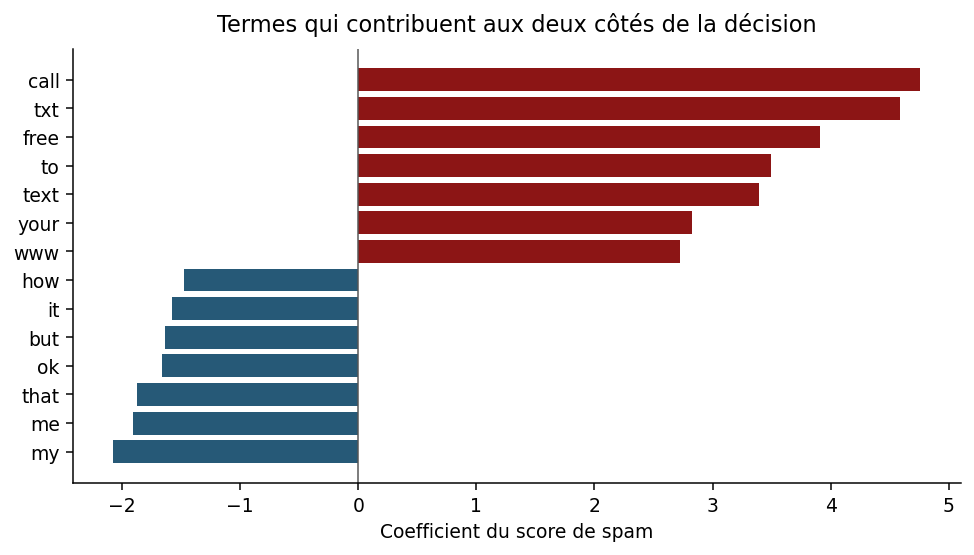

In [24]:
vectorizer = best_pipeline.named_steps['tfidf']
model = best_pipeline.named_steps['model']
feature_names = vectorizer.get_feature_names_out()
if isinstance(model, LogisticRegression):
    weights = model.coef_[0]
    weight_label = 'Coefficient du score de spam'
else:
    weights = model.feature_log_prob_[1] - model.feature_log_prob_[0]
    weight_label = 'Différence de log-poids · spam moins légitime'
selected = np.r_[np.argsort(weights)[:7], np.argsort(weights)[-7:]]
weight_table = pd.DataFrame({
    'term': feature_names[selected], 'weight': weights[selected],
}).sort_values('weight')
fig, ax = plt.subplots(figsize=(7.1, 4.0), layout='constrained')
ax.barh(weight_table['term'], weight_table['weight'],
        color=np.where(weight_table['weight'] > 0, red, blue))
ax.axvline(0, color='#555555', linewidth=0.8)
ax.set(xlabel=weight_label, title='Termes qui contribuent aux deux côtés de la décision')
plt.show()

### Essayer des messages rédigés pour l'exemple

Les quatre textes suivants sont des exemples pédagogiques en anglais, langue
du corpus. Les sorties illustrent le comportement de la chaîne. Elles ne
suffisent pas à mesurer son efficacité.

In [25]:
X_new = pd.Series([
    'Are we still meeting at 6? I will bring your notes.',
    'Congratulations! You won a free cash prize. Call now to claim.',
    'Your parcel is delayed. Pay the small delivery fee using this link.',
    'Can you call me when you arrive home?',
])
new_scores = best_pipeline.predict_proba(X_new)[:, 1]
display(pd.DataFrame({
    'text': X_new, 'score': new_scores,
    'flag_as_spam': (new_scores >= decision_threshold).astype(int),
}).round(4))

,text,score,flag_as_spam
0,Are we still meeting at 6? I will bring your n...,0.1309,0
1,Congratulations! You won a free cash prize. Ca...,0.9725,1
2,Your parcel is delayed. Pay the small delivery...,0.4100,0
3,Can you call me when you arrive home?,0.0867,0


## 7. Conclusion et préparation au projet d'examen

La conclusion doit relier le filtre à son usage. Rapporter la population,
le retrait des doublons, les trois ensembles, la métrique, le modèle, le seuil,
les SMS légitimes masqués et les spams manqués. Préciser aussi les limites
liées à la langue et à l'ancienneté du corpus.

In [26]:
final_row = test_results.iloc[1]
project_summary = {
    'dataset': 'SMS Spam Collection · UCI · DOI 10.24432/C5CC84',
    'raw_rows': len(raw_data), 'clean_rows': len(data),
    'train_rows': len(X_train), 'threshold_validation_rows': len(X_valid), 'test_rows': len(X_test),
    'model': type(best_pipeline.named_steps['model']).__name__,
    'sampler': str(best_pipeline.named_steps['sampler']),
    'vocabulary_size': len(feature_names), 'best_cv_average_precision': best_cv_score,
    'selection_source': selection_source,
    'decision_threshold': decision_threshold, 'test_average_precision': float(test_ap),
    'test_precision': float(final_row['precision']), 'test_recall': float(final_row['recall']),
    'test_false_negatives': int(final_row['FN']), 'test_false_positives': int(final_row['FP']),
    'test_flagged_messages': int(final_predictions.sum()),
}
display(pd.Series(project_summary, name='result').to_frame())

,result
dataset,SMS Spam Collection · UCI · DOI 10.24432/C5CC84
raw_rows,5574
clean_rows,5159
train_rows,3095
threshold_validation_rows,1032
test_rows,1032
model,LogisticRegression
sampler,passthrough
vocabulary_size,5000
best_cv_average_precision,0.974208


### Conclusion du projet

Après retrait des répétitions, le corpus contient 5159 SMS.
L'EDA, les comparaisons et le tuning utilisent 3095 messages.
La comparaison de tous les candidats retient LogisticRegression avec une AP CV de
0.974. Le pipeline apprend un vocabulaire
de 5000 termes.

La règle de seuil est choisie sur 1032 messages
avec un objectif de precision d'au moins 95 %. Le seuil retenu vaut
0.597.

Sur les 1032 SMS réservés au test, cette règle retrouve
113 spams, en manque 15 et signale à tort
10 messages légitimes. La precision vaut 91.9%
et le recall 88.3%. L'AP test est 0.970.

Au seuil 0,5, on retrouve 120 spams, avec 15
faux positifs et 8 spams manqués. Le choix du seuil doit être
discuté selon l'usage du dossier indésirables et la possibilité de récupérer
un message légitime.

Les résultats portent sur un corpus ancien en anglais, dédupliqué selon une règle
précise. Ils ne suffisent pas à mesurer un filtre de SMS français récents.
Le corpus manque aussi de dates et d'identifiants de conversation. La prochaine
expérience réserverait des messages récents d'une population définie, avec une
séparation adaptée à l'usage et un critère de filtrage annoncé avant l'évaluation.


### À vous · défendre et améliorer le filtre

1. Pourquoi retirer les SMS répétés avant le partage ? Que changerait la présence
   d'un identifiant de conversation ou d'expéditeur ?
2. Une copie ajuste TF–IDF sur tous les textes puis fait SMOTE avant le split.
   Repérer les deux fuites et écrire l'ordre corrigé.
3. Expliquer pourquoi un point créé par SMOTE n'est pas un nouveau SMS.
4. Comparer 0,5 et le seuil validé avec les FP et FN. Quelle règle conseiller
   pour un dossier indésirables ? Quelles informations manquent sur l'usage ?
5. Proposer une évaluation sur des SMS français récents, avec dates, sans adapter
   le modèle sur le test du projet.

<details><summary>Éléments de correction</summary>

1. Une copie dans les deux ensembles rend la tâche artificiellement facile.
   Avec les conversations ou expéditeurs, choisir une séparation par groupe selon
   l'usage visé.
2. Séparer les textes bruts, puis placer TF–IDF et le sampler dans ImbPipeline
   au sein de chaque pli. Le vocabulaire est un état appris.
3. Le point contient des poids de mots interpolés. Il ne définit pas une phrase.
4. Nommer le coût des SMS légitimes masqués et des spams restants. Le seuil vise
   une precision sur validation, sans garantie sur toute population future.
5. Garder un test récent indépendant. Les choix de langue, de corpus, de modèle
   et de seuil doivent être faits avant son ouverture.
</details>

### Sources et attribution

- [SMS Spam Collection, Almeida et Hidalgo, UCI](https://archive.ics.uci.edu/dataset/228/sms+spam+collection),
  DOI 10.24432/C5CC84, CC BY 4.0. Fichier original et Readme inclus.
- [TF–IDF et représentation des textes](https://scikit-learn.org/1.4/modules/feature_extraction.html#text-feature-extraction)
- [Multinomial Naive Bayes](https://scikit-learn.org/1.4/modules/naive_bayes.html#multinomial-naive-bayes)
- [Cross-validation](https://scikit-learn.org/1.4/modules/cross_validation.html)
- [Hyperparameter tuning](https://scikit-learn.org/1.4/modules/grid_search.html)
- [Imbalanced-learn et fuites de données](https://imbalanced-learn.org/stable/common_pitfalls.html)